# 03 · Tránsitos de TESS, masas y densidades de LHS 1140 b y c

**Idea del cuaderno:** buscar los tránsitos de los dos planetas en TESS **sin suponer los periodos**, ajustarlos con `batman` para sacar los radios, y juntarlos con las masas mínimas que salieron de RadVel para tener masa, radio y densidad de cada planeta.

En el informe esto es el **análisis independiente** de los tránsitos (sección III.D). Los radios finales del informe salen del ajuste MCMC de Mateo; aquí la idea era ver si llegábamos a lo mismo por otro camino más sencillo (y sí, quedan dentro de 1σ).

Pasos:
1. Bajar las curvas de luz de TESS (sectores 3, 30 y 107).
2. Limpiarlas y aplanarlas.
3. BLS para encontrar el primer planeta, taparlo y buscar el segundo.
4. Arreglar el alias del periodo de b usando el periodo de las velocidades radiales.
5. Ajustar cada tránsito con `batman`.
6. Masas con los resultados de RadVel, densidades y diagrama masa-radio.

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk

## Curvas de luz de TESS
Buscamos curvas de **SPOC** con cadencia de 120 s. Salen **3 sectores**: 3 (2018), 30 (2020) y 107 (2026).

In [26]:
busqueda = lk.search_lightcurve('LHS 1140', mission='TESS', author='SPOC', exptime=120)
busqueda

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 03,2018,SPOC,120,92226327,0.0
1,TESS Sector 30,2020,SPOC,120,92226327,0.0
2,TESS Sector 107,2026,SPOC,120,92226327,0.0


Las bajamos todas y las graficamos. El aviso de la máscara de calidad es normal: TESS marca puntos malos (descargas de momento, luz dispersa, etc.) y esos se ignoran.

In [27]:
coleccion = busqueda.download_all()
coleccion.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

## Limpiar la curva
`stitch()` une los sectores, `flatten()` quita la variación lenta de la estrella (filtro Savitzky–Golay) y `remove_outliers()` quita puntos raros.

Ojo con los límites de sigma: arriba cortamos en 4σ pero abajo en 20σ, para **no borrar los tránsitos**, que son caídas de flujo.

**Quedan 42 963 puntos.**

In [28]:
lc = coleccion.stitch().flatten(window_length=721).remove_outliers(sigma_upper=4, sigma_lower=20)
lc.plot()
print("Número de puntos:", len(lc))

Número de puntos: 42963


## Primera búsqueda con BLS
BLS (*box least squares*) prueba muchos periodos y duraciones y busca la caída en forma de caja que mejor encaja. Binamos la curva a ~10 min para que no se demore tanto.

**Resultado:** la señal más fuerte da **P ≈ 26.57 d**, que se parece a b pero **no** es el periodo que reporta la literatura (24.74 d). Como b solo tiene 3 tránsitos separados por años, hay muchos periodos que los pueden unir: esto es un **alias**. Lo arreglamos más abajo.

In [29]:
lc_bin = lc.bin(time_bin_size=0.007).remove_nans() 

T = lc_bin.time.value.max() - lc_bin.time.value.min()
frecuencias = np.arange(1/30, 1/1, 0.003 / T)
periodos = 1 / frecuencias
duraciones = [0.03, 0.05, 0.08, 0.12]
print("Tiempo total:", T, "días.  Periodos a probar:", len(periodos))

bls1 = lc_bin.to_periodogram(method='bls', period=periodos, duration=duraciones, frequency_factor=1000)
bls1.plot()
plt.xscale('log')

P1   = float(bls1.period_at_max_power.value)
t01  = float(bls1.transit_time_at_max_power.value)
dur1 = float(bls1.duration_at_max_power.value)
print("Señal 1:  P =", P1, " T0 =", t01, " duración =", dur1 * 24, "h")

`period` contains 271892 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


Tiempo total: 2904.8320000131384 días.  Periodos a probar: 936002
Señal 1:  P = 26.569703237524358  T0 = 1399.929465292972  duración = 1.944 h


Curva plegada con ese periodo, para ver que sí hay un tránsito.

In [30]:
lc.fold(period=P1, epoch_time=t01).bin(time_bin_size=0.005).scatter()
plt.xlim(-0.3, 0.3)

(-0.3, 0.3)

## Segundo planeta
Tapamos los tránsitos de la primera señal y volvemos a correr BLS.

**Resultado:** **P ≈ 3.7779 d**, que es LHS 1140 c. Este sí sale bien a la primera porque tiene 17 tránsitos.

In [31]:
mascara1_bin = lc_bin.create_transit_mask(period=P1, transit_time=t01, duration=2 * dur1)

bls2 = lc_bin[~mascara1_bin].to_periodogram(method='bls', period=periodos, duration=duraciones, frequency_factor=1000)
bls2.plot()
plt.xscale('log')

P2   = float(bls2.period_at_max_power.value)
t02  = float(bls2.transit_time_at_max_power.value)
dur2 = float(bls2.duration_at_max_power.value)
print("Señal 2:  P =", P2, " T0 =", t02, " duración =", dur2 * 24, "h")

`period` contains 271892 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


Señal 2:  P = 3.777936890466405  T0 = 1389.292965292972  duración = 0.72 h


Guardamos qué señal es cada planeta.

In [32]:
P_b, t0_b, dur_b = P1, t01, dur1
P_c, t0_c, dur_c = P2, t02, dur2

## Arreglar el alias de b
Las velocidades radiales dicen que b tiene un periodo de unos 24.74 d, así que buscamos solo en ±0.5 d alrededor de ese valor (con los tránsitos de c tapados).

**Resultado:** **P_b ≈ 24.737 d**, ya de acuerdo con la literatura. Aquí se ve por qué sirve combinar VR y tránsitos.

In [33]:
P_vr_b = 24.74

mascara_c_bin = lc_bin.create_transit_mask(period=P_c, transit_time=t0_c, duration=2 * dur_c)
cerca_vr = np.abs(periodos - P_vr_b) < 0.5

bls_alias = lc_bin[~mascara_c_bin].to_periodogram(method='bls', period=periodos[cerca_vr], duration=duraciones, frequency_factor=1000)
bls_alias.plot()

P_b   = float(bls_alias.period_at_max_power.value)
t0_b  = float(bls_alias.transit_time_at_max_power.value)
dur_b = float(bls_alias.duration_at_max_power.value)
print("b (cerca del periodo de VR):  P =", P_b, " T0 =", t0_b, " duración =", dur_b * 24, "h")

b (cerca del periodo de VR):  P = 24.73697805933097  T0 = 1399.935465292972  duración = 1.944 h


## Afinar periodos y épocas
Repetimos BLS en una ventana muy angosta alrededor de cada periodo y con duraciones más finas, pero ahora en la curva sin binar. Para b tapamos a c y viceversa.

**Resultado:**
- b: P = 24.73727 d, duración ≈ 1.9 h
- c: P = 3.77794 d, duración ≈ 1.0 h

In [34]:
mascara_c = lc.create_transit_mask(period=P_c, transit_time=t0_c, duration=2 * dur_c)
mascara_b = lc.create_transit_mask(period=P_b, transit_time=t0_b, duration=2 * dur_b)
lc_sin_c = lc[~mascara_c]      # para estudiar b
lc_sin_b = lc[~mascara_b]      # para estudiar c

duraciones_finas = np.linspace(0.02, 0.15, 14)

bls_b = lc_sin_c.to_periodogram(method='bls', period=np.linspace(P_b * 0.999, P_b * 1.001, 3000), duration=duraciones_finas, frequency_factor=1000)
P_b   = float(bls_b.period_at_max_power.value)
t0_b  = float(bls_b.transit_time_at_max_power.value)
dur_b = float(bls_b.duration_at_max_power.value)

bls_c = lc_sin_b.to_periodogram(method='bls', period=np.linspace(P_c * 0.999, P_c * 1.001, 3000), duration=duraciones_finas, frequency_factor=1000)
P_c   = float(bls_c.period_at_max_power.value)
t0_c  = float(bls_c.transit_time_at_max_power.value)
dur_c = float(bls_c.duration_at_max_power.value)

print(f"b:  P = {P_b:.5f} d   T0 = {t0_b:.4f} BTJD   duración = {dur_b*24:.2f} h")
print(f"c:  P = {P_c:.5f} d   T0 = {t0_c:.4f} BTJD   duración = {dur_c*24:.2f} h")

b:  P = 24.73727 d   T0 = 1399.9275 BTJD   duración = 1.92 h
c:  P = 3.77794 d   T0 = 1389.2935 BTJD   duración = 0.96 h


## Volver a aplanar, ahora tapando los tránsitos
El primer `flatten()` no sabía dónde estaban los tránsitos y los puede "comer" un poco (los hace menos profundos). Ahora que ya sabemos dónde están, aplanamos otra vez la curva original pero con los tránsitos de b y c enmascarados.

In [35]:
crudo = coleccion.stitch()
mascara_ambos = crudo.create_transit_mask(period=[P_b, P_c], transit_time=[t0_b, t0_c], duration=[2 * dur_b, 2 * dur_c])

lc = crudo.flatten(window_length=721, mask=mascara_ambos).remove_outliers(sigma_upper=4, sigma_lower=20)

lc_sin_c = lc[~lc.create_transit_mask(period=P_c, transit_time=t0_c, duration=2 * dur_c)]
lc_sin_b = lc[~lc.create_transit_mask(period=P_b, transit_time=t0_b, duration=2 * dur_b)]

## Radio aproximado con la profundidad
Antes de ajustar, una cuenta rápida: la profundidad del tránsito es más o menos (R_p/R★)², entonces R_p ≈ √δ · R★.

Usamos el radio de la estrella de Cadieux et al. (2024): R★ = 0.2159 ± 0.0030 R☉.

**Resultado:** b ≈ 1.91 R⊕ y c ≈ 1.38 R⊕. Es solo para tener valores iniciales; el ajuste de abajo es el que vale.

In [36]:
R_estrella   = 0.2159       # R☉, Cadieux et al. 2024
sR_estrella  = 0.0030
R_sol_en_R_tierra = 109.08  # 1 R☉ = 109.08 R⊕

R_estrella_t = R_estrella * R_sol_en_R_tierra   # radio de la estrella en R⊕

plegada_b = lc_sin_c.fold(period=P_b, epoch_time=t0_b)
tiempo = plegada_b.time.value
flujo  = plegada_b.flux.value
dentro = np.abs(tiempo) < dur_b / 4
fuera  = np.abs(tiempo) > dur_b
delta_b  = np.median(flujo[fuera]) - np.median(flujo[dentro])
sdelta_b = np.std(flujo[fuera]) / np.sqrt(dentro.sum())

plegada_c = lc_sin_b.fold(period=P_c, epoch_time=t0_c)
tiempo = plegada_c.time.value
flujo  = plegada_c.flux.value
dentro = np.abs(tiempo) < dur_c / 4
fuera  = np.abs(tiempo) > dur_c
delta_c  = np.median(flujo[fuera]) - np.median(flujo[dentro])
sdelta_c = np.std(flujo[fuera]) / np.sqrt(dentro.sum())

print(f"b: profundidad = {delta_b*1e3:.2f} ± {sdelta_b*1e3:.2f} ppt  →  Rp ≈ {np.sqrt(delta_b)*R_estrella_t:.2f} R⊕")
print(f"c: profundidad = {delta_c*1e3:.2f} ± {sdelta_c*1e3:.2f} ppt  →  Rp ≈ {np.sqrt(delta_c)*R_estrella_t:.2f} R⊕")

b: profundidad = 6.56 ± 0.24 ppt  →  Rp ≈ 1.91 R⊕
c: profundidad = 3.45 ± 0.15 ppt  →  Rp ≈ 1.38 R⊕


## Modelo de tránsito con `batman`
- `a_sobre_R`: calcula a/R★ con la tercera ley de Kepler usando la masa y el radio de la estrella. Así no hay que ajustarlo.
- `modelo_transito`: el modelo de `batman` con órbita circular y oscurecimiento al limbo cuadrático (u₁ = 0.2, u₂ = 0.4, aproximado para una estrella de 3100 K en la banda de TESS).

Los parámetros libres son solo tres: **k = R_p/R★**, el **parámetro de impacto b** y un pequeño corrimiento del centro.

**Resultado:** a/R★ ≈ 94.2 para b y ≈ 26.9 para c.

In [37]:
import batman
from scipy.optimize import curve_fit

M_estrella = 0.1844          # M☉, Cadieux et al. 2024
u_limbo = [0.2, 0.4]         # oscurecimiento al limbo (aprox., Claret 2017)

def a_sobre_R(P):
    # Tercera ley de Kepler: tamaño de la órbita en radios estelares
    G = 6.674e-11
    M_sol = 1.989e30         # kg
    R_sol = 6.957e8          # m
    a = (G * M_estrella * M_sol * (P * 86400)**2 / (4 * np.pi**2))**(1/3)
    return a / (R_estrella * R_sol)

def modelo_transito(t, rp, b_imp, dt):
    p = batman.TransitParams()
    p.t0  = dt
    p.per = P_ajuste
    p.rp  = rp
    p.a   = aR_ajuste
    p.inc = np.degrees(np.arccos(b_imp / aR_ajuste))
    p.ecc = 0.0
    p.w   = 90.0
    p.limb_dark = "quadratic"
    p.u   = u_limbo
    return batman.TransitModel(p, t).light_curve(p)

print("a/R★ de b:", a_sobre_R(P_b), "   a/R★ de c:", a_sobre_R(P_c))

a/R★ de b: 94.1982958433106    a/R★ de c: 26.914013560554462


## Ajuste de LHS 1140 b
`curve_fit` de SciPy sobre la curva plegada, usando solo los puntos cerca del tránsito (±3 duraciones). El error de cada punto es la dispersión fuera del tránsito.

**Resultado:** R_p/R★ = 0.0745 ± 0.0012, b = 0.29, i ≈ 89.8°.

In [38]:
P_ajuste  = P_b
aR_ajuste = a_sobre_R(P_b)

t_b = plegada_b.time.value
f_b = plegada_b.flux.value
cerca = np.abs(t_b) < 3 * dur_b
t_b, f_b = t_b[cerca], f_b[cerca]
error_b = np.std(f_b[np.abs(t_b) > dur_b])

p0 = [np.sqrt(delta_b), 0.3, 0.0]
limites = ([0.0, 0.0, -0.02], [0.3, 0.99, 0.02])
popt_b, pcov_b = curve_fit(modelo_transito, t_b, f_b, p0=p0, sigma=np.full(len(t_b), error_b), bounds=limites)
perr_b = np.sqrt(np.diag(pcov_b))

rp_b, b_imp_b, dt_b = popt_b
srp_b = perr_b[0]
inc_b = np.degrees(np.arccos(b_imp_b / aR_ajuste))
print(f"b:  Rp/R★ = {rp_b:.4f} ± {srp_b:.4f}   b = {b_imp_b:.2f} ± {perr_b[1]:.2f}   i = {inc_b:.2f}°")

b:  Rp/R★ = 0.0745 ± 0.0012   b = 0.29 ± 0.05   i = 89.82°


## Ajuste de LHS 1140 c
Lo mismo para c (los límites de los parámetros son los de la celda anterior).

**Resultado:** R_p/R★ = 0.0527 ± 0.0010, b = 0.19, i ≈ 89.6°.

In [39]:
P_ajuste  = P_c
aR_ajuste = a_sobre_R(P_c)

t_c = plegada_c.time.value
f_c = plegada_c.flux.value
cerca = np.abs(t_c) < 3 * dur_c
t_c, f_c = t_c[cerca], f_c[cerca]
error_c = np.std(f_c[np.abs(t_c) > dur_c])

p0 = [np.sqrt(delta_c), 0.3, 0.0]
popt_c, pcov_c = curve_fit(modelo_transito, t_c, f_c, p0=p0, sigma=np.full(len(t_c), error_c), bounds=limites)
perr_c = np.sqrt(np.diag(pcov_c))

rp_c, b_imp_c, dt_c = popt_c
srp_c = perr_c[0]
inc_c = np.degrees(np.arccos(b_imp_c / aR_ajuste))
print(f"c:  Rp/R★ = {rp_c:.4f} ± {srp_c:.4f}   b = {b_imp_c:.2f} ± {perr_c[1]:.2f}   i = {inc_c:.2f}°")

c:  Rp/R★ = 0.0527 ± 0.0010   b = 0.19 ± 0.08   i = 89.59°


Gráfica de los dos tránsitos: en gris los puntos, en rojo los promedios cada ~10 min y en azul el modelo. Los dos se ven bien definidos; el de b es más profundo y más largo.

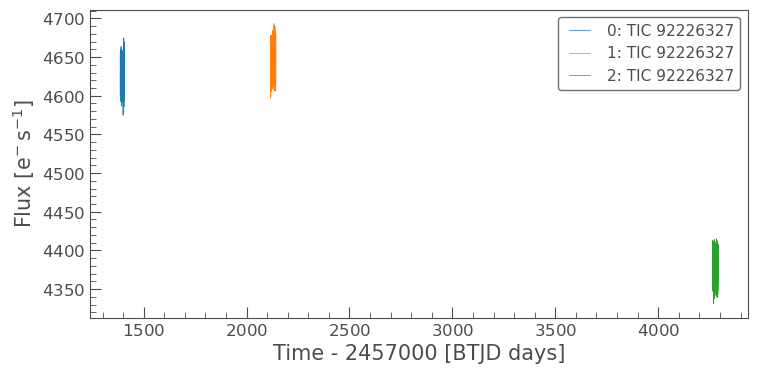

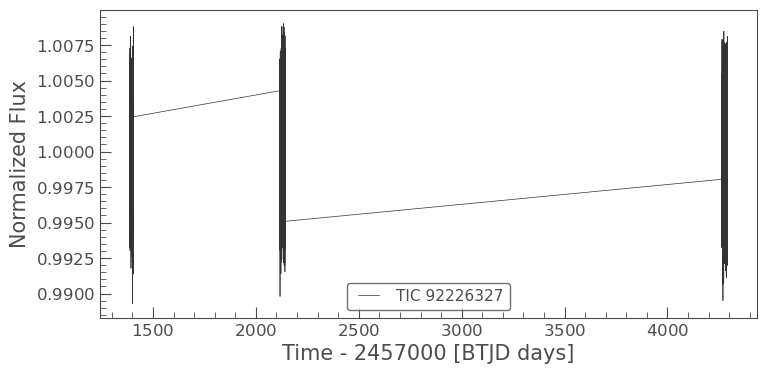

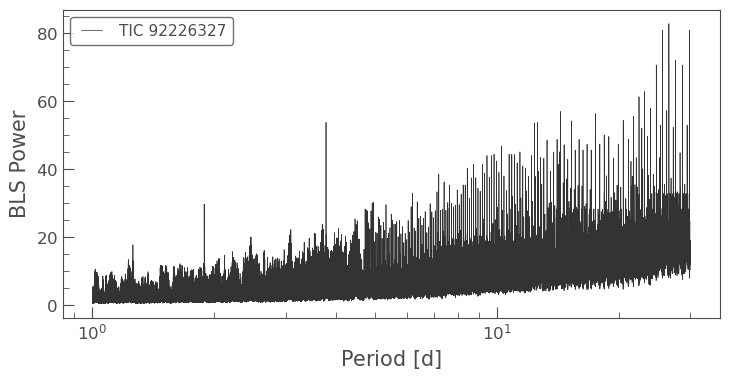

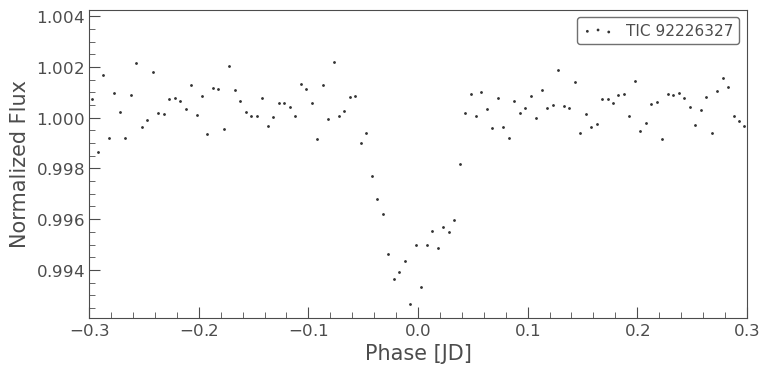

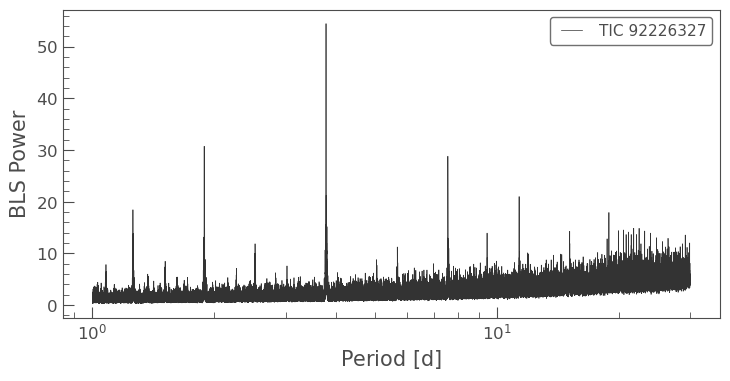

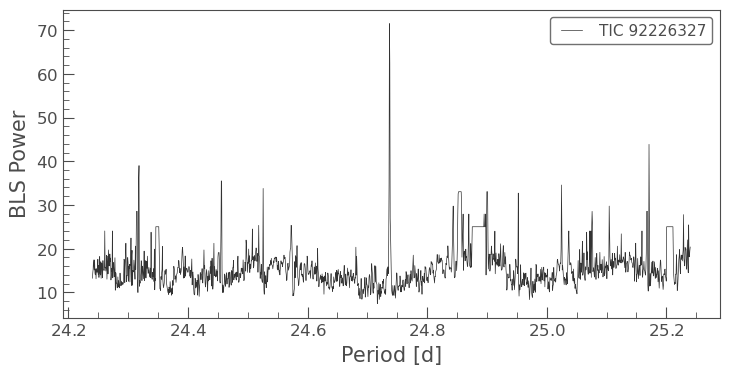

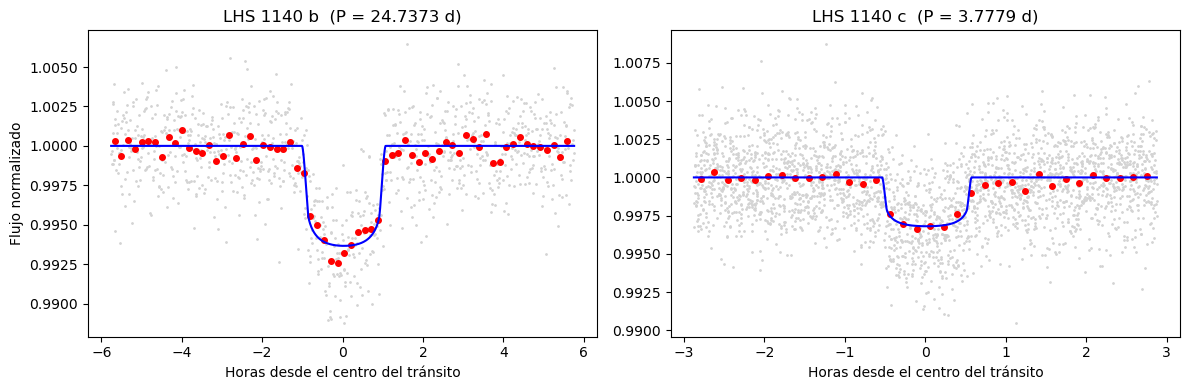

In [40]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
planetas = [("b", t_b, f_b, popt_b, P_b), ("c", t_c, f_c, popt_c, P_c)]

for ax, (nombre, t, f, popt, P) in zip(ejes, planetas):
    P_ajuste  = P
    aR_ajuste = a_sobre_R(P)
    orden = np.argsort(t)
    t, f = t[orden], f[orden]

    cajas = np.arange(t.min(), t.max(), 0.007)
    centros = (cajas[:-1] + cajas[1:]) / 2
    promedios = [np.mean(f[(t >= cajas[i]) & (t < cajas[i + 1])]) for i in range(len(cajas) - 1)]

    ax.plot(t * 24, f, ".", color="lightgray", ms=2)
    ax.plot(centros * 24, promedios, "o", color="red", ms=4)
    ax.plot(t * 24, modelo_transito(t, *popt), color="blue")
    ax.set_xlabel("Horas desde el centro del tránsito")
    ax.set_title(f"LHS 1140 {nombre}  (P = {P:.4f} d)")
ejes[0].set_ylabel("Flujo normalizado")
plt.tight_layout()
plt.show()

## Radios en radios terrestres
R_p = k · R★, propagando el error de k y el de R★.

**Resultado:**
- **R_b = 1.755 ± 0.037 R⊕**
- **R_c = 1.242 ± 0.029 R⊕**

Son los mismos del informe para este análisis, y coinciden dentro de 1σ con los del MCMC de Mateo (1.78 y 1.25 R⊕), que son los que quedaron como finales.

In [41]:
R_b  = rp_b * R_estrella_t
sR_b = R_b * np.sqrt((srp_b / rp_b)**2 + (sR_estrella / R_estrella)**2)
R_c  = rp_c * R_estrella_t
sR_c = R_c * np.sqrt((srp_c / rp_c)**2 + (sR_estrella / R_estrella)**2)

print(f"R_b = {R_b:.3f} ± {sR_b:.3f} R⊕")
print(f"R_c = {R_c:.3f} ± {sR_c:.3f} R⊕")

R_b = 1.755 ± 0.037 R⊕
R_c = 1.242 ± 0.029 R⊕


## Masas con los resultados de RadVel
Leemos los cuantiles de las masas mínimas (M_p sin i) que guardó RadVel en el ajuste **circular** con ESPRESSO, y dividimos por sin i usando la inclinación del tránsito. Como i ≈ 90°, sin i ≈ 1 y la masa casi no cambia.

> **Ojo:** la ruta apunta a la carpeta de Descargas de JuanDa. En el repo los resultados están en `resultados_radvel/circular/`, así que para correrlo hay que cambiar la ruta a ese archivo.

**Resultado:**
- **M_b = 4.51 ± 1.11 M⊕**
- **M_c = 1.37 ± 0.44 M⊕**

In [42]:
import pandas as pd

ruta = "/home/juan/Downloads/TOI233_MX_BR_ESP_1GP_ecross_RADVEL_EXAMPLE/TOI233_MX_BR_ESP_1GP_ecross_RADVEL_EXAMPLE_derived_quantiles.csv"
q = pd.read_csv(ruta, index_col=0)
print(q[["mpsini1", "mpsini2"]])

Msini_b  = q["mpsini1"].iloc[1]
sMsini_b = (q["mpsini1"].iloc[2] - q["mpsini1"].iloc[0]) / 2
Msini_c  = q["mpsini2"].iloc[1]
sMsini_c = (q["mpsini2"].iloc[2] - q["mpsini2"].iloc[0]) / 2

M_b,  sM_b = Msini_b / np.sin(np.radians(inc_b)), sMsini_b / np.sin(np.radians(inc_b))
M_c,  sM_c = Msini_c / np.sin(np.radians(inc_c)), sMsini_c / np.sin(np.radians(inc_c))
print(f"\nM_b = {M_b:.2f} ± {sM_b:.2f} M⊕   (sin i = {np.sin(np.radians(inc_b)):.5f})")
print(f"M_c = {M_c:.2f} ± {sM_c:.2f} M⊕   (sin i = {np.sin(np.radians(inc_c)):.5f})")

        mpsini1   mpsini2
0.159  3.347884  0.991078
0.500  4.505312  1.372984
0.841  5.563964  1.867751

M_b = 4.51 ± 1.11 M⊕   (sin i = 1.00000)
M_c = 1.37 ± 0.44 M⊕   (sin i = 0.99997)


## Densidades
ρ = 5.51 g/cm³ · (M/M⊕) / (R/R⊕)³. Como el radio va al cubo, su error pesa el triple que el de la masa.

**Resultado:** ρ_b ≈ 4.6 ± 1.2 g/cm³ y ρ_c ≈ 4.0 ± 1.3 g/cm³. Las dos son menores que la de la Tierra (5.51 g/cm³).

In [43]:
rho_b  = 5.51 * M_b / R_b**3
srho_b = rho_b * np.sqrt((sM_b / M_b)**2 + (3 * sR_b / R_b)**2)
rho_c  = 5.51 * M_c / R_c**3
srho_c = rho_c * np.sqrt((sM_c / M_c)**2 + (3 * sR_c / R_c)**2)

print(f"ρ_b = {rho_b:.2f} ± {srho_b:.2f} g/cm³")
print(f"ρ_c = {rho_c:.2f} ± {srho_c:.2f} g/cm³")

ρ_b = 4.60 ± 1.17 g/cm³
ρ_c = 3.95 ± 1.29 g/cm³


## Diagrama masa-radio (versión rápida)
Comparamos con dos curvas simples: composición terrestre y roca pura, y ponemos los valores de Cadieux et al. (2024) en gris. El diagrama completo con los modelos de Zeng, Aguichine y Tang se hizo aparte con `mr-plotter` (ver informe, sección III.F).

Lo que se ve: los radios coinciden muy bien con la literatura, pero nuestras masas quedan más bajitas (con barras de error mucho más grandes, porque usamos 44 espectros y no 117).

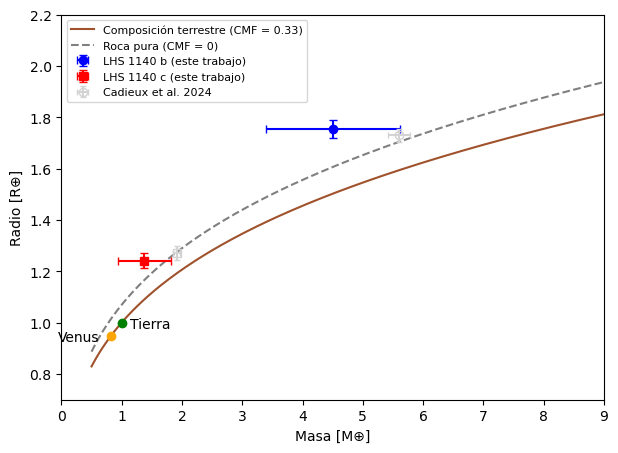

In [44]:
M = np.linspace(0.5, 10, 200)
R_tierra = (1.07 - 0.21 * 0.33) * M**(1 / 3.7)
R_roca   = 1.07 * M**(1 / 3.7)

plt.figure(figsize=(7, 5))
plt.plot(M, R_tierra, color="sienna", label="Composición terrestre (CMF = 0.33)")
plt.plot(M, R_roca, color="gray", ls="--", label="Roca pura (CMF = 0)")

plt.errorbar(M_b, R_b, xerr=sM_b, yerr=sR_b, fmt="o", color="blue", capsize=3, label="LHS 1140 b (este trabajo)")
plt.errorbar(M_c, R_c, xerr=sM_c, yerr=sR_c, fmt="s", color="red", capsize=3, label="LHS 1140 c (este trabajo)")

plt.errorbar(5.60, 1.730, xerr=0.19, yerr=0.025, fmt="o", mfc="none", color="lightgray", capsize=2, label="Cadieux et al. 2024")
plt.errorbar(1.91, 1.272, xerr=0.06, yerr=0.026, fmt="s", mfc="none", color="lightgray", capsize=2)

plt.plot(1, 1, "o", color="green")
plt.annotate("Tierra", (1, 1), textcoords="offset points", xytext=(6, -4))
plt.plot(0.815, 0.949, "o", color="orange")
plt.annotate("Venus", (0.815, 0.949), textcoords="offset points", xytext=(-38, -4))

plt.xlabel("Masa [M⊕]")
plt.ylabel("Radio [R⊕]")
plt.xlim(0, 9)
plt.ylim(0.7, 2.2)
plt.legend(fontsize=8)
plt.show()

## Tabla final
Comparación con Cadieux et al. (2024). Los periodos son prácticamente iguales, los radios coinciden dentro de 1σ y las masas quedan a ~1–1.4σ por debajo.

In [45]:
tabla = pd.DataFrame({
    "Este trabajo b": [f"{P_b:.5f}", f"{R_b:.2f} ± {sR_b:.2f}", f"{M_b:.2f} ± {sM_b:.2f}", f"{rho_b:.1f} ± {srho_b:.1f}"],
    "Cadieux+24 b":   ["24.73723", "1.730 ± 0.025", "5.60 ± 0.19", "—"],
    "Este trabajo c": [f"{P_c:.5f}", f"{R_c:.2f} ± {sR_c:.2f}", f"{M_c:.2f} ± {sM_c:.2f}", f"{rho_c:.1f} ± {srho_c:.1f}"],
    "Cadieux+24 c":   ["3.77794", "1.272 ± 0.026", "1.91 ± 0.06", "—"],
}, index=["P [d]", "R [R⊕]", "M [M⊕]", "ρ [g/cm³]"])
tabla

,Este trabajo b,Cadieux+24 b,Este trabajo c,Cadieux+24 c
P [d],24.73727,24.73723,3.77794,3.77794
R [R⊕],1.75 ± 0.04,1.730 ± 0.025,1.24 ± 0.03,1.272 ± 0.026
M [M⊕],4.51 ± 1.11,5.60 ± 0.19,1.37 ± 0.44,1.91 ± 0.06
ρ [g/cm³],4.6 ± 1.2,—,3.9 ± 1.3,—
